## Installing Libraries

In [1]:
!pip install grad-cam -q

import warnings
warnings.filterwarnings('ignore')

print("✅ Libraries installed successfully")

✅ Libraries installed successfully


## Import and Configure Path

In [2]:
import os
import random
import copy
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm
from collections import Counter

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import DataLoader, WeightedRandomSampler

import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
import torchvision.models as models   # ResNet-50

# Grad-CAM
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("✅ Libraries imported successfully!")
print(f"🖥️ Device : {DEVICE}")

if torch.cuda.is_available():
    print(f"🎮 GPU : {torch.cuda.get_device_name(0)}")

# Kaggle Dataset Paths (No need to modify)

BASE_PATH = r"C:\Users\ayanl\OneDrive\Desktop\MTech-Project\OSCC_Histopathological_Dataset"

TRAIN_PATH = os.path.join(BASE_PATH, "train")
VAL_PATH   = os.path.join(BASE_PATH, "val")
TEST_PATH  = os.path.join(BASE_PATH, "test")

# Folder to save trained models, plots, confusion matrix, etc.
SAVE_DIR = os.path.join(BASE_PATH, "Results")
os.makedirs(SAVE_DIR, exist_ok=True)

# Verify Dataset Paths

for name, path in [
    ("Training", TRAIN_PATH),
    ("Validation", VAL_PATH),
    ("Testing", TEST_PATH)
]:
    status = "✅ Found" if os.path.exists(path) else "❌ Not Found"
    print(f"{status}: {name} Dataset -> {path}")

# Display Class Names

if os.path.exists(TRAIN_PATH):
    print("\nClasses Found:")
    print(sorted(os.listdir(TRAIN_PATH)))

✅ Libraries imported successfully!
🖥️ Device : cpu
✅ Found: Training Dataset -> C:\Users\ayanl\OneDrive\Desktop\MTech-Project\OSCC_Histopathological_Dataset\train
✅ Found: Validation Dataset -> C:\Users\ayanl\OneDrive\Desktop\MTech-Project\OSCC_Histopathological_Dataset\val
✅ Found: Testing Dataset -> C:\Users\ayanl\OneDrive\Desktop\MTech-Project\OSCC_Histopathological_Dataset\test

Classes Found:
['Normal', 'OSCC']


## Exploratory Data Analysis

📊 Dataset Distribution
Class               Train  Validation      Test     Total
-------------------------------------------------------
Normal               2435          28        31      2494
OSCC                 2511          92        95      2698
TOTAL                4946         120       126      5192


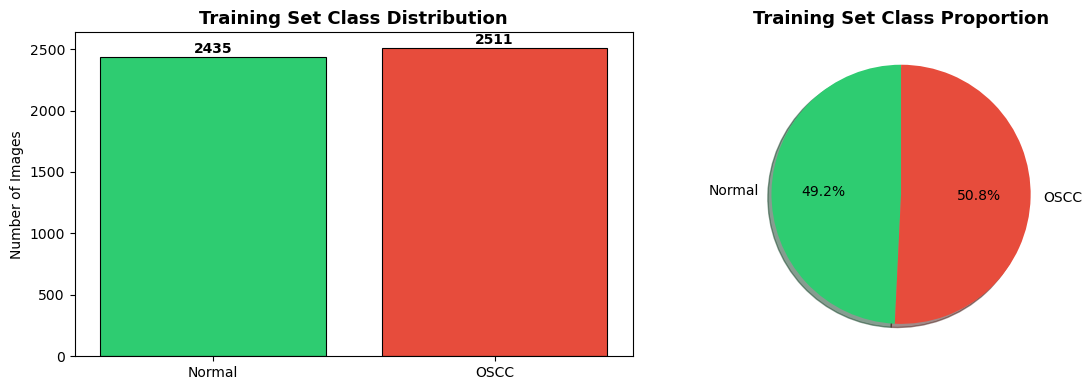

✅ Dataset distribution plot saved successfully!


In [3]:
# Dataset Distribution Analysis

dataset_counts = {}

for split_name, split_path in [
    ("train", TRAIN_PATH),
    ("val", VAL_PATH),
    ("test", TEST_PATH)
]:
    dataset_counts[split_name] = {}

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            dataset_counts[split_name][class_name] = len([
                file for file in os.listdir(class_path)
                if file.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff"))
            ])

# Training class distribution
train_counts = dataset_counts["train"]
class_names = sorted(train_counts.keys())

# Display Dataset Statistics
print("📊 Dataset Distribution")
print("=" * 55)
print(f"{'Class':<15}{'Train':>10}{'Validation':>12}{'Test':>10}{'Total':>10}")
print("-" * 55)

for class_name in class_names:
    train = dataset_counts["train"].get(class_name, 0)
    val = dataset_counts["val"].get(class_name, 0)
    test = dataset_counts["test"].get(class_name, 0)

    print(f"{class_name:<15}{train:>10}{val:>12}{test:>10}{train + val + test:>10}")

total_train = sum(dataset_counts["train"].values())
total_val = sum(dataset_counts["val"].values())
total_test = sum(dataset_counts["test"].values())

print("=" * 55)
print(f"{'TOTAL':<15}{total_train:>10}{total_val:>12}{total_test:>10}{total_train + total_val + total_test:>10}")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

colors = ["#2ecc71", "#e74c3c"]

# Bar Chart
bars = axes[0].bar(
    train_counts.keys(),
    train_counts.values(),
    color=colors,
    edgecolor="black",
    linewidth=0.8
)

axes[0].set_title(
    "Training Set Class Distribution",
    fontsize=13,
    fontweight="bold"
)

axes[0].set_ylabel("Number of Images")

for bar, count in zip(bars, train_counts.values()):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        str(count),
        ha="center",
        va="bottom",
        fontweight="bold"
    )

# Pie Chart
axes[1].pie(
    train_counts.values(),
    labels=train_counts.keys(),
    colors=colors,
    autopct="%1.1f%%",
    startangle=90,
    shadow=True
)

axes[1].set_title(
    "Training Set Class Proportion",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()

# Save Figure
plt.savefig(
    os.path.join(SAVE_DIR, "dataset_distribution.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("✅ Dataset distribution plot saved successfully!")

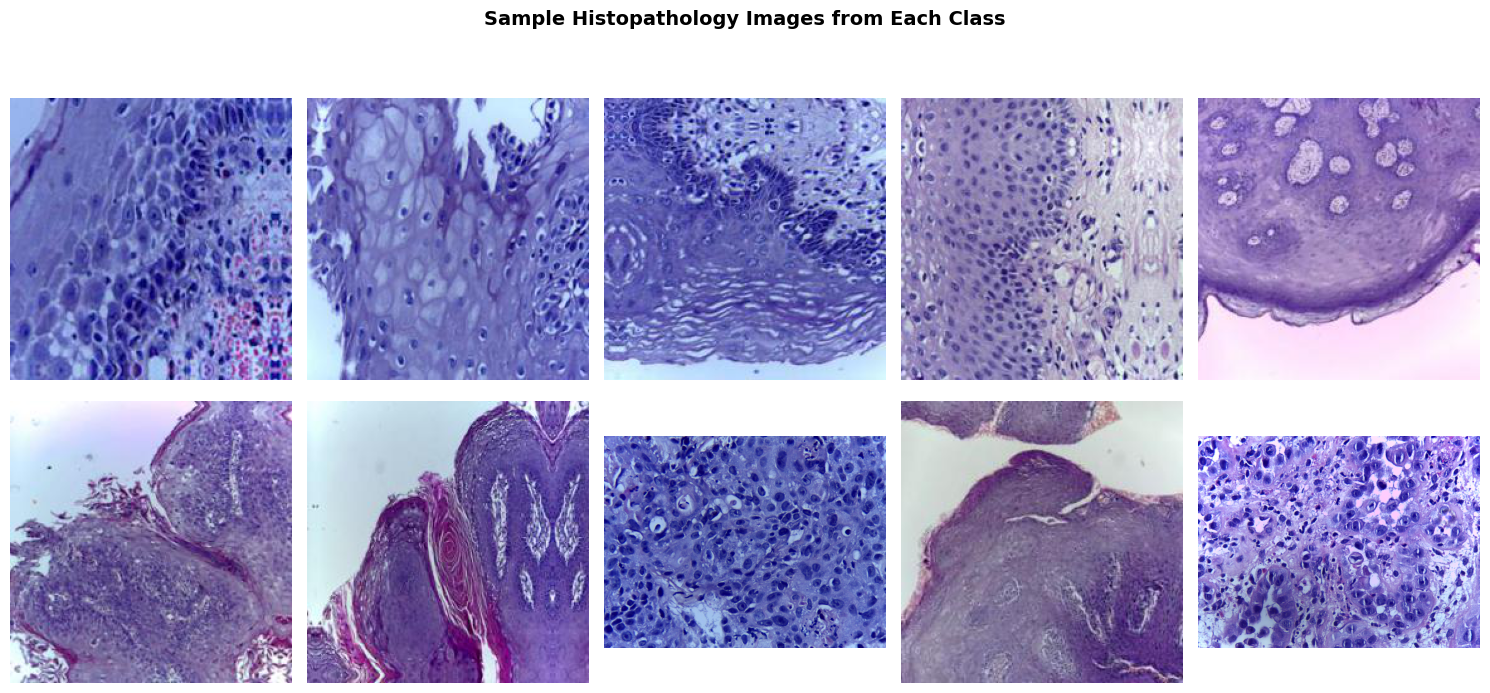

✅ Sample images saved successfully!


In [4]:
# Display Sample Images from Each Class
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

fig.suptitle(
    "Sample Histopathology Images from Each Class",
    fontsize=14,
    fontweight="bold",
    y=1.02
)

for row, class_name in enumerate(sorted(train_counts.keys())):

    class_path = os.path.join(TRAIN_PATH, class_name)

    image_files = [
        file for file in os.listdir(class_path)
        if file.lower().endswith((".png", ".jpg", ".jpeg", ".tif", ".tiff"))
    ]

    # Randomly select up to 5 images
    sample_images = random.sample(image_files, min(5, len(image_files)))

    for col, image_name in enumerate(sample_images):

        image = Image.open(
            os.path.join(class_path, image_name)
        ).convert("RGB")

        axes[row, col].imshow(image)
        axes[row, col].axis("off")

        # Display class label on the first image of each row
        if col == 0:

            label_color = "#27ae60" if class_name.lower() == "normal" else "#c0392b"

            axes[row, col].set_ylabel(
                class_name,
                fontsize=11,
                fontweight="bold",
                color=label_color,
                rotation=90,
                va="center",
                labelpad=10
            )

plt.tight_layout()

# Save the figure
plt.savefig(
    os.path.join(SAVE_DIR, "sample_histopathology_images.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("✅ Sample images saved successfully!")

## Data-Preprocessing and Data Loader

In [5]:
# Data Preprocessing and Data Loading
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 4

# Training Data Preprocessing
train_transform = transforms.Compose([

    # Resize all images to 224 × 224 pixels
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    # Randomly flip images horizontally
    transforms.RandomHorizontalFlip(p=0.5),

    # Randomly flip images vertically
    transforms.RandomVerticalFlip(p=0.5),

    # Randomly rotate images up to ±30°
    transforms.RandomRotation(degrees=30),

    # Randomly adjust brightness, contrast,
    # saturation, and hue
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.15,
        hue=0.05
    ),

    # Randomly translate the image by up to 5%
    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05)
    ),

    # Convert image into PyTorch tensor
    transforms.ToTensor(),

    # Normalize pixel values using ImageNet statistics
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),

    # Randomly erase a small region of the image
    # to improve model robustness
    transforms.RandomErasing(
        p=0.2,
        scale=(0.02, 0.1)
    )
])

# Validation and Test Data Preprocessing
val_test_transform = transforms.Compose([

    # Resize images
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    # Convert to tensor
    transforms.ToTensor(),

    # Normalize pixel values
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load Dataset
train_dataset = ImageFolder(
    TRAIN_PATH,
    transform=train_transform
)

val_dataset = ImageFolder(
    VAL_PATH,
    transform=val_test_transform
)

test_dataset = ImageFolder(
    TEST_PATH,
    transform=val_test_transform
)

CLASS_NAMES = train_dataset.classes
NUM_CLASSES = len(CLASS_NAMES)

print(f"Classes       : {CLASS_NAMES}")
print(f"Class Mapping : {train_dataset.class_to_idx}")

# Weighted Random Sampler (Balances class sampling during training)
train_labels = [label for _, label in train_dataset.samples]

class_counts = Counter(train_labels)

class_weights = {
    cls: 1.0 / count
    for cls, count in class_counts.items()
}

sample_weights = [
    class_weights[label]
    for label in train_labels
]

sampler = WeightedRandomSampler(
    sample_weights,
    len(sample_weights)
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

# Dataset Summary
print("\n✅ DataLoaders created successfully!")

print(f"Training Images   : {len(train_dataset):5d} | {len(train_loader)} batches")
print(f"Validation Images : {len(val_dataset):5d} | {len(val_loader)} batches")
print(f"Testing Images    : {len(test_dataset):5d} | {len(test_loader)} batches")

Classes       : ['Normal', 'OSCC']
Class Mapping : {'Normal': 0, 'OSCC': 1}

✅ DataLoaders created successfully!
Training Images   :  4946 | 155 batches
Validation Images :   120 | 4 batches
Testing Images    :   126 | 4 batches


## Implementing Baseline Model : ResNet-50

In [6]:
class ResNet50Classifier(nn.Module):
    def __init__(self, num_classes=2, dropout=0.4):
        super().__init__()

        # Load pretrained ResNet-50
        self.backbone = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

        # Number of input features in the final fully connected layer
        in_features = self.backbone.fc.in_features

        # Replace the original classifier
        self.backbone.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(in_features, num_classes)
        )

    def forward(self, x):
        return self.backbone(x)

# Test the Model
dummy = torch.randn(2, 3, 224, 224)

model = ResNet50Classifier(num_classes=NUM_CLASSES)

output = model(dummy)

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("✅ ResNet-50 Model Created Successfully!")
print(f"Output Shape      : {tuple(output.shape)}")
print(f"Trainable Parameters : {num_params:,}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\ayanl/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100%|█████████████████████████████████████████████████████████████████████████████| 97.8M/97.8M [00:30<00:00, 3.34MB/s]


✅ ResNet-50 Model Created Successfully!
Output Shape      : (2, 2)
Trainable Parameters : 23,512,130


## Training and Evaluation

In [7]:
def train_model(model, train_loader, val_loader, model_name, num_epochs=30):

    # Move model to CPU/GPU
    model = model.to(DEVICE)

    # Class weights for handling class imbalance
    class_weights = [1.0 / class_counts[i] for i in range(NUM_CLASSES)]

    criterion = nn.CrossEntropyLoss(
        weight=torch.FloatTensor(class_weights).to(DEVICE)
    )

    # Optimizer
    optimizer = optim.Adam(
        model.parameters(),
        lr=1e-4,
        weight_decay=1e-5
    )

    # Learning Rate Scheduler
    scheduler = ReduceLROnPlateau(
        optimizer,
        mode='max',
        factor=0.5,
        patience=5
    )

    # Store training history
    history = {
        "train_loss": [],
        "train_accuracy": [],
        "validation_loss": [],
        "validation_accuracy": []
    }

    best_validation_accuracy = 0.0
    best_model_weights = None

    print("=" * 70)
    print(f"Training Model : {model_name}")
    print("=" * 70)

    # Training Loop
    for epoch in range(num_epochs):

        # ---------------- Training ----------------
        model.train()

        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for images, labels in tqdm(
            train_loader,
            desc=f"Epoch {epoch + 1}/{num_epochs}",
            leave=False
        ):

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            # Gradient Clipping
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()

            running_loss += loss.item() * images.size(0)

            predicted = outputs.argmax(dim=1)

            correct_predictions += (predicted == labels).sum().item()

            total_samples += labels.size(0)

        train_loss = running_loss / total_samples
        train_accuracy = correct_predictions / total_samples

        # ---------------- Validation ----------------

        model.eval()

        validation_loss = 0.0
        validation_correct = 0
        validation_samples = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(DEVICE)
                labels = labels.to(DEVICE)

                outputs = model(images)

                loss = criterion(outputs, labels)

                validation_loss += loss.item() * images.size(0)

                predicted = outputs.argmax(dim=1)

                validation_correct += (predicted == labels).sum().item()

                validation_samples += labels.size(0)

        validation_loss /= validation_samples
        validation_accuracy = validation_correct / validation_samples

        # Store History

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["validation_loss"].append(validation_loss)
        history["validation_accuracy"].append(validation_accuracy)

        # Update Learning Rate

        scheduler.step(validation_accuracy)

        # Save Best Model

        if validation_accuracy > best_validation_accuracy:

            best_validation_accuracy = validation_accuracy

            best_model_weights = copy.deepcopy(model.state_dict())

            torch.save(
                best_model_weights,
                os.path.join(
                    SAVE_DIR,
                    f"best_{model_name.replace(' ', '_')}.pth"
                )
            )

        # Print Progress

        print(
            f"Epoch [{epoch + 1:02d}/{num_epochs}] | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Accuracy: {train_accuracy:.4f} | "
            f"Validation Loss: {validation_loss:.4f} | "
            f"Validation Accuracy: {validation_accuracy:.4f}"
        )

    print("\nTraining Completed Successfully!")
    print(f"Best Validation Accuracy : {best_validation_accuracy:.4f}")

    # Load Best Model

    model.load_state_dict(best_model_weights)

    return model, history


print("Training function is ready.")

Training function is ready.


In [8]:
def evaluate_model(model, test_loader, model_name):

    # Set model to evaluation mode
    model.eval()

    all_predictions = []
    all_labels = []
    all_probabilities = []

    # Disable gradient computation during evaluation
    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(DEVICE)

            outputs = model(images)

            probabilities = torch.softmax(outputs, dim=1)

            predictions = outputs.argmax(dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    # Convert lists to NumPy arrays
    all_predictions = np.array(all_predictions)
    all_labels = np.array(all_labels)
    all_probabilities = np.array(all_probabilities)

    # Calculate Classification Metrics
    report = classification_report(
        all_labels,
        all_predictions,
        target_names=CLASS_NAMES,
        output_dict=True
    )

    # Calculate ROC-AUC Score (Binary Classification)
    auc_score = None

    if NUM_CLASSES == 2:
        auc_score = roc_auc_score(
            all_labels,
            all_probabilities[:, 1]
        )

    # Print Evaluation Results
    print("\n" + "=" * 70)
    print(f"Evaluation Results : {model_name}")
    print("=" * 70)

    print(classification_report(
        all_labels,
        all_predictions,
        target_names=CLASS_NAMES
    ))

    if auc_score is not None:
        print(f"AUC-ROC Score : {auc_score:.4f}")


    # Confusion Matrix
    cm = confusion_matrix(all_labels, all_predictions)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.title(
        f"Confusion Matrix - {model_name}",
        fontsize=14,
        fontweight="bold"
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            SAVE_DIR,
            f"confusion_matrix_{model_name.replace(' ', '_').lower()}.png"
        ),
        dpi=150
    )

    plt.show()

    # Return Evaluation Metrics
    results = {
        "accuracy": report["accuracy"],
        "precision": report["macro avg"]["precision"],
        "recall": report["macro avg"]["recall"],
        "f1_score": report["macro avg"]["f1-score"],
        "auc_roc": auc_score,
        "probabilities": all_probabilities,
        "true_labels": all_labels
    }

    return results


print("Evaluation function is ready.")

Evaluation function is ready.


## Training ResNet-50 Model

In [9]:
NUM_EPOCHS = 30
results    = {}

Training ResNet-50 Model...
Training Model : ResNet50


Epoch [01/30] | Train Loss: 0.3981 | Train Accuracy: 0.8168 | Validation Loss: 0.3244 | Validation Accuracy: 0.8500


Epoch [02/30] | Train Loss: 0.1955 | Train Accuracy: 0.9220 | Validation Loss: 0.3695 | Validation Accuracy: 0.8583


Epoch [03/30] | Train Loss: 0.1400 | Train Accuracy: 0.9442 | Validation Loss: 0.2689 | Validation Accuracy: 0.8917


Epoch [04/30] | Train Loss: 0.1108 | Train Accuracy: 0.9581 | Validation Loss: 0.5451 | Validation Accuracy: 0.8333


...

Epoch [26/30] | Train Loss: 0.0157 | Train Accuracy: 0.9931 | Validation Loss: 0.6136 | Validation Accuracy: 0.9167


Epoch [27/30] | Train Loss: 0.0198 | Train Accuracy: 0.9921 | Validation Loss: 0.7413 | Validation Accuracy: 0.9083


Epoch [28/30] | Train Loss: 0.0177 | Train Accuracy: 0.9919 | Validation Loss: 0.6718 | Validation Accuracy: 0.8917


Epoch [29/30] | Train Loss: 0.0121 | Train Accuracy: 0.9939 | Validation Loss: 0.7724 | Validation Accuracy: 0.8917


Epoch [30/30] | Train Loss: 0.0131 | Train Accuracy: 0.9919 | Validation Loss: 0.7256 | Validation Accuracy: 0.8917

Training Completed Successfully!
Best Validation Accuracy : 0.9333

Evaluation Results : ResNet50
              precision    recall  f1-score   support

      Normal       0.80      0.77      0.79        31
        OSCC       0.93      0.94      0.93        95

    accuracy                           0.90       126
   macro avg       0.86      0.86      0.86       126
weighted avg       0.90      0.90      0.90       126

AUC-ROC Score : 0.9450


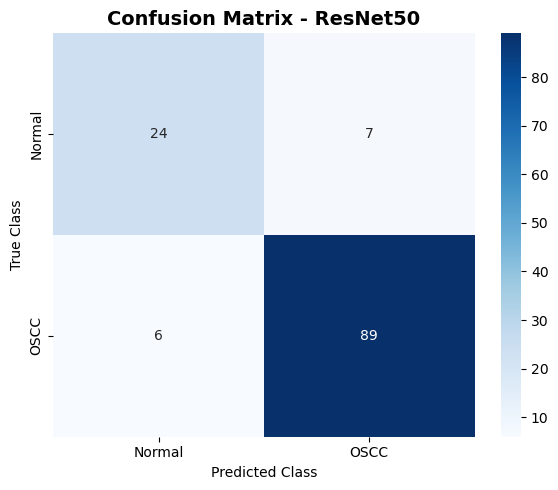


✅ ResNet-50 training and evaluation completed successfully!
💾 Model saved to: C:\Users\ayanl\OneDrive\Desktop\MTech-Project\OSCC_Histopathological_Dataset\Results\model_resnet50.pth


In [10]:
print("Training ResNet-50 Model...")

# Train the model
model_resnet50, history_resnet50 = train_model(
    ResNet50Classifier(num_classes=NUM_CLASSES),
    train_loader,
    val_loader,
    model_name="ResNet50",
    num_epochs=NUM_EPOCHS
)

# Save the trained model
torch.save(
    model_resnet50.state_dict(),
    os.path.join(SAVE_DIR, "model_resnet50.pth")
)

# Evaluate the model
results["ResNet50"] = evaluate_model(
    model_resnet50,
    test_loader,
    model_name="ResNet50"
)

# Save training history
results["ResNet50"]["history"] = history_resnet50

print("\n✅ ResNet-50 training and evaluation completed successfully!")
print(f"💾 Model saved to: {os.path.join(SAVE_DIR, 'model_resnet50.pth')}")

## Plot training and Validation Curves

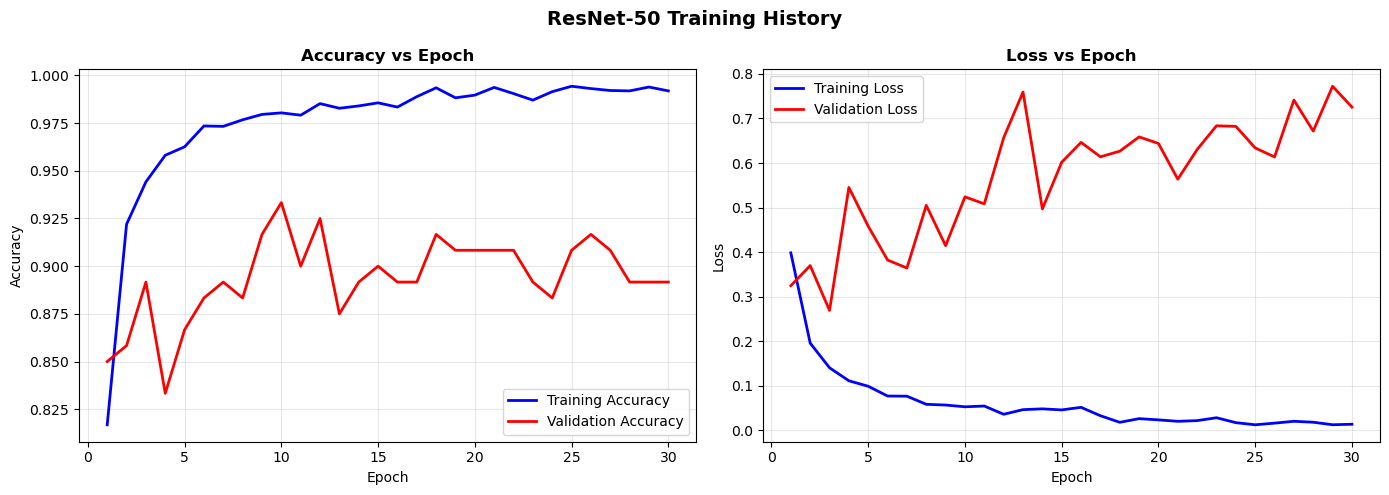

✅ Training curves saved successfully!


In [11]:
history = results["ResNet50"]["history"]

epochs = range(1, len(history["train_accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fig.suptitle(
    "ResNet-50 Training History",
    fontsize=14,
    fontweight="bold"
)

# Accuracy Curve
axes[0].plot(
    epochs,
    history["train_accuracy"],
    label="Training Accuracy",
    color="blue",
    linewidth=2
)

axes[0].plot(
    epochs,
    history["validation_accuracy"],
    label="Validation Accuracy",
    color="red",
    linewidth=2
)

axes[0].set_title("Accuracy vs Epoch", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss Curve
axes[1].plot(
    epochs,
    history["train_loss"],
    label="Training Loss",
    color="blue",
    linewidth=2
)

axes[1].plot(
    epochs,
    history["validation_loss"],
    label="Validation Loss",
    color="red",
    linewidth=2
)

axes[1].set_title("Loss vs Epoch", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        SAVE_DIR,
        "resnet50_training_curves.png"
    ),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("✅ Training curves saved successfully!")

## Grad-CAM++ Visualization for ResNet-50

In [12]:
def run_gradcam_pp(model, num_samples=8):

    # Target layer: Last convolutional block of ResNet-50
    target_layers = [model.backbone.layer4[-1]]

    cam = GradCAMPlusPlus(
        model=model,
        target_layers=target_layers
    )

    indices = random.sample(
        range(len(test_dataset)),
        min(num_samples, len(test_dataset))
    )

    fig, axes = plt.subplots(3, num_samples, figsize=(num_samples * 2.5, 8))

    fig.suptitle(
        "Grad-CAM++ Visualization - ResNet-50\n"
        "Row 1: Original Image | "
        "Row 2: Grad-CAM Heatmap | "
        "Row 3: Overlay",
        fontsize=12,
        fontweight="bold"
    )

    model.eval()

    for col, idx in enumerate(indices):

        # Load image
        image_tensor, true_label = test_dataset[idx]

        image_path = test_dataset.samples[idx][0]

        original_image = np.array(
            Image.open(image_path)
            .convert("RGB")
            .resize((224, 224))
        ) / 255.0

        input_tensor = image_tensor.unsqueeze(0).to(DEVICE)

        # Generate Grad-CAM++
        grayscale_cam = cam(
            input_tensor=input_tensor,
            targets=[ClassifierOutputTarget(true_label)]
        )[0]

        # Prediction
        with torch.no_grad():
            prediction = model(input_tensor).argmax(dim=1).item()

        correct = prediction == true_label

        symbol = "✓" if correct else "✗"
        color = "green" if correct else "red"

        visualization = show_cam_on_image(
            original_image.astype(np.float32),
            grayscale_cam,
            use_rgb=True
        )

        # Original Image
        axes[0, col].imshow(original_image)
        axes[0, col].axis("off")
        axes[0, col].set_title(
            f"True\n{CLASS_NAMES[true_label]}",
            fontsize=8
        )

        # Heatmap
        axes[1, col].imshow(grayscale_cam, cmap="jet")
        axes[1, col].axis("off")
        axes[1, col].set_title(
            "Heatmap",
            fontsize=8
        )

        # Overlay
        axes[2, col].imshow(visualization)
        axes[2, col].axis("off")
        axes[2, col].set_title(
            f"Pred\n{CLASS_NAMES[prediction]} {symbol}",
            fontsize=8,
            color=color
        )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            SAVE_DIR,
            "gradcampp_resnet50.png"
        ),
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

    print("✅ Grad-CAM++ visualization saved successfully!")

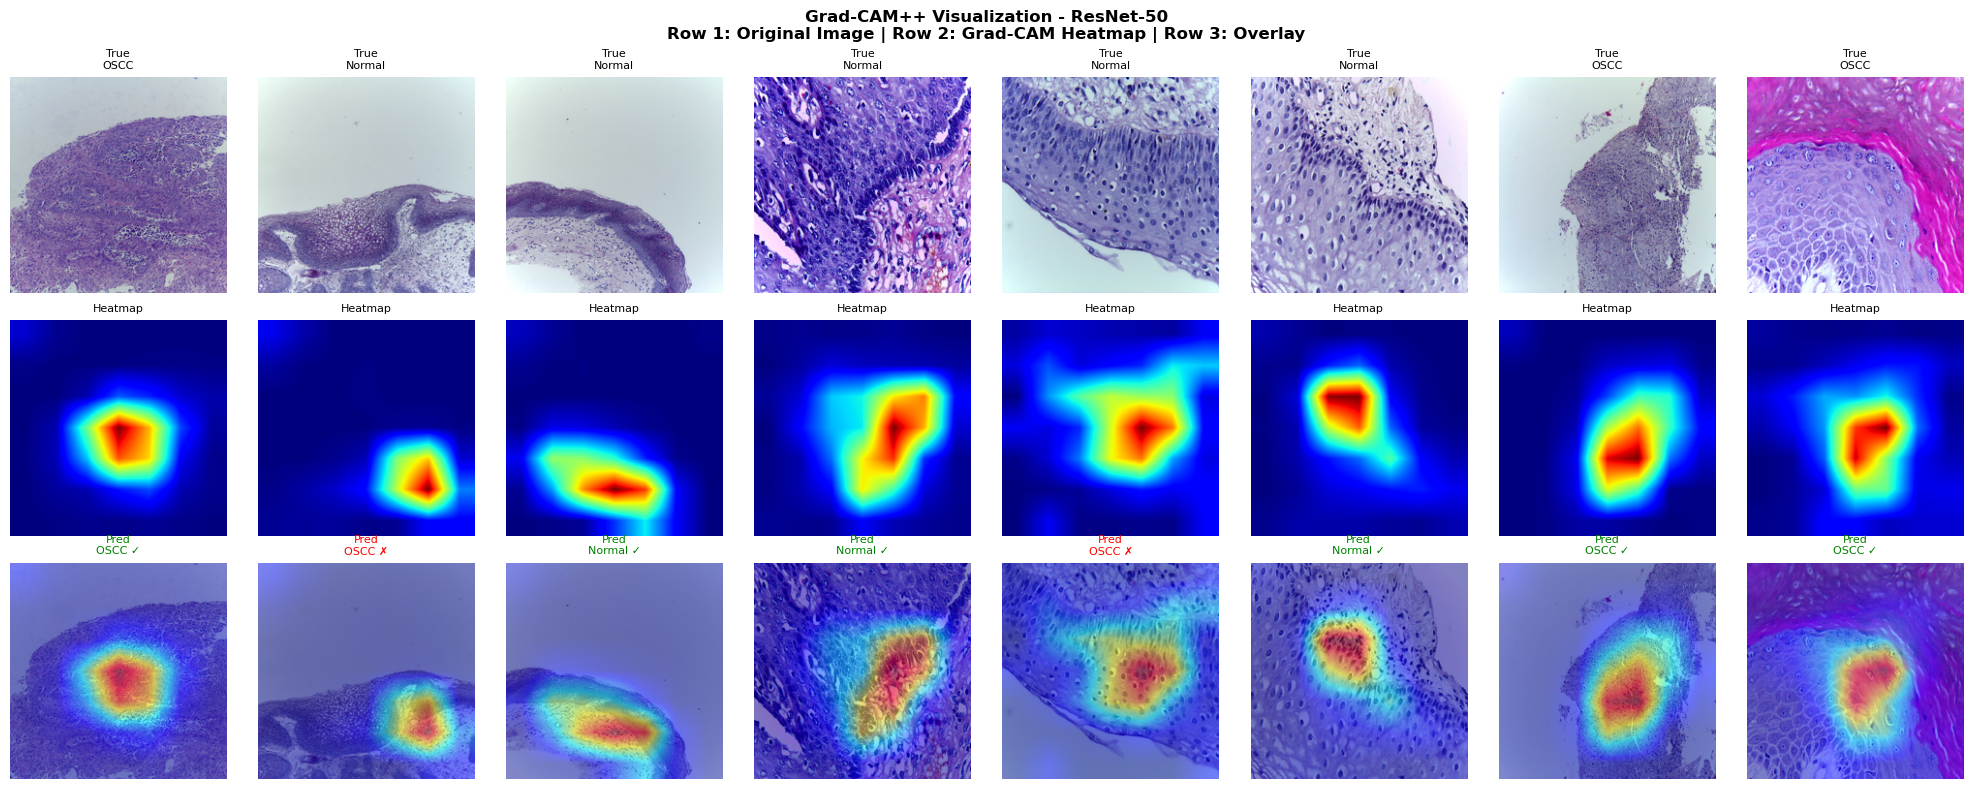

✅ Grad-CAM++ visualization saved successfully!


In [13]:
# Put the model in evaluation mode
model_resnet50.eval()

# Generate Grad-CAM++ visualizations
run_gradcam_pp(model_resnet50, num_samples=8)